In [1]:
from google.colab import drive
drive.mount('/content/drive')
import sys
from pathlib import Path
ROOT = Path("/content/drive/MyDrive/NLP-final-2026-main")
sys.path.insert(0, str(ROOT / "src"))
import torch
gpu_available = torch.cuda.is_available()
print(f"GPU Available: {gpu_available}")
if gpu_available:
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

Mounted at /content/drive
GPU Available: True
Device Name: Tesla T4


# Legal QA over US housing (landlord-tenant) law: M1 / M2 / M3 pipeline
**One-run pipeline:** *Runtime -> Run all*. Prerequisites: the project folder is on Google Drive at `MyDrive/NLP-final-2026-main`, and notebooks 01-03
(teammate: data, preprocessing, BM25 indexes in `data/index/`) have been run once. This notebook then covers everything else:
training M1 (scratch) and M2 (fine-tuned), M3 (retrieval-augmented), evaluation, error analysis, the optional citation extension and the final report.
Every number in the report section is computed by the cells below; nothing is typed in by hand.

In [2]:
%pip install -q bm25s PyStemmer sentencepiece

In [3]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from legal_qa.data import HousingQA
from legal_qa.data.indexing import state_index_dir
from legal_qa.data.splitting import split_summary
from legal_qa.evaluation import metrics as M
from legal_qa.modeling.train import TrainConfig, train, generate, load_best, load_tokenizer, get_device, SEED
from legal_qa.paths import FIGURES_DIR, MODELS_DIR, PROCESSED_DIR, TABLES_DIR
from legal_qa.retrieval.retriever import cache_retrieval, make_rag_records, top_statute_hits, cite

for d in (MODELS_DIR, FIGURES_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- pre-flight checks: fail early with a clear message instead of deep inside a cell
assert ROOT.exists(), f"Project folder not found: {ROOT}"
for s in ("train", "val", "test"):
    assert (PROCESSED_DIR / f"{s}.jsonl").exists(), f"missing data/processed/{s}.jsonl - run notebook 02 first"
splits = HousingQA().splits()                      # train / val / test only (train_aux is not used by M1/M2)
missing = sorted({r["state"] for s in ("val", "test") for r in splits[s] if not state_index_dir(r["state"]).exists()})
assert not missing, f"BM25 index missing for {missing}: run 03-build-corpus-index.ipynb first (data/index/ must be on Drive)"
device, tok = get_device(), load_tokenizer()
print("device:", device, "| seed:", SEED, "| sizes:", {k: len(v) for k, v in splits.items()})

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

device: cuda | seed: 42 | sizes: {'train': 5505, 'val': 650, 'test': 689}


## 1. Task, scope and data
- **Task:** sequence-to-sequence QA. Input `state: <State> question: <question>`; output a short English answer.
- **Topic / jurisdiction / scope:** residential landlord-tenant and eviction law of 48 US jurisdictions (statutes as of 2021).
- **Dataset:** `reglab/housing_qa` (questions with gold statutes; statutes corpus used for retrieval). **Pretrained model:** `google/flan-t5-small`. **Retriever:** per-state BM25 (`bm25s`).
- **Answer format:** HousingQA answers are **Yes/No**, so a "short answer" is one word. This gives objective labels but means token-F1 equals exact match, and a trivial "always no" baseline is strong - the evaluation below accounts for both.

In [4]:
display(pd.read_csv(TABLES_DIR / "qa_examples.csv")[["state", "question", "answer", "citation"]])
# Split table recomputed over train/val/test only (the stored split_summary.csv counts train_aux in the denominator)
split_table = split_summary(splits); display(split_table)
print("train_aux rows (excluded from training):", sum(1 for _ in open(PROCESSED_DIR / "train_aux.jsonl", encoding="utf-8")))

,state,question,answer,citation
0,District of Columbia,Is it specified in which court eviction cases ...,Yes,D.C. CODE § 42-3210
1,Alaska,Is it specified for what reasons a landlord mu...,Yes,ALASKA STAT. § 9.45.690
2,Delaware,Does inclement weather postpone the execution ...,No,DEL CODE TIT. 25 § 5715
3,Indiana,"In an eviction action, can a tenant use landlo...",No,IND. CODE § 32-30-2-5
4,Colorado,Primary methods of service are defined as thos...,No,COLO. REV. STAT. § 13-40-112(1)


,split,n_questions,share,n_groups,n_states,n_yes,n_no,yes_ratio
0,train,5505,0.804,180,48,1963,3542,0.357
1,val,650,0.095,22,48,191,459,0.294
2,test,689,0.101,23,48,257,432,0.373


train_aux rows (excluded from training): 1877


**Preprocessing and splits (done in notebooks 01-03).** Whitespace normalised; conflicting duplicate (state, question) rows dropped; split 80/10/10 **by `question_group`**
(GroupShuffleSplit, seed 42), so the same question text never appears in two splits. Tokenization: Flan-T5 SentencePiece, max source length 128 tokens, max target length 4
(`yes`/`no` + EOS). M3 documents: statutes chunked into 100-word windows with 20-word overlap, one BM25 index per state; only statutes are indexed, so test questions and answers are not in the index.

In [5]:
# Leakage / difficulty checks on the test set
from sklearn.feature_extraction.text import TfidfVectorizer
tr_q = sorted({r["question"] for r in splits["train"]}); te_q = sorted({r["question"] for r in splits["test"]})
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(tr_q + te_q)
sim = (vec.transform(te_q) @ vec.transform(tr_q).T).toarray().max(1)
exact_overlap = set(tr_q) & set(te_q)
golds_test = [r["target_text"] for r in splits["test"]]
print(f"exact question-text overlap train/test: {len(exact_overlap)}")
print(f"distinct test question texts: {len(te_q)} (rows: {len(golds_test)}); near-duplicates of a train question: cosine>0.9: {(sim > 0.9).sum()}, >0.8: {(sim > 0.8).sum()}")

exact question-text overlap train/test: 0
distinct test question texts: 23 (rows: 689); near-duplicates of a train question: cosine>0.9: 2, >0.8: 6


## 2. Training M1 (scratch) and M2 (fine-tuned)
Same architecture (Flan-T5-small config, 77M parameters), same tokenizer, same training split, same loss (token-level cross-entropy), same optimizer family
(AdamW, weight decay 0.01, linear warm-up 6% then linear decay, gradient clipping 1.0, batch 32, bf16 autocast when available).
**Only the initial weights differ.** Validation every 25 steps; **checkpoint selection criterion = lowest validation loss**; validation accuracy is a diagnostic only.

In [6]:
CONFIGS = {
    # random init needs a larger LR and more epochs; both runs stop early on validation loss
    "m1_scratch":   TrainConfig(name="m1_scratch",   init="scratch",    lr=1e-3, epochs=30, batch_size=32, eval_every=25, patience=12),
    "m2_finetuned": TrainConfig(name="m2_finetuned", init="pretrained", lr=3e-4, epochs=10, batch_size=32, eval_every=25, patience=8),
}
histories = {}
for name, cfg in CONFIGS.items():
    print("=" * 30, name)
    histories[name] = train(cfg, splits["train"], splits["val"], MODELS_DIR / name, tokenizer=tok, device=device)

============================== m1_scratch


Training:   0%|          | 0/5190 [00:00<?, ?step/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step    25/5190 | Epoch 0.14 | Train Loss: 49.6170 | Val Loss: 1.4401 | Val Acc: 0.669 | Best: 1.4401 | Patience: 0/12 | Elapsed: 24s | NEW BEST
Step    50/5190 | Epoch 0.29 | Train Loss: 3.0092 | Val Loss: 2.2713 | Val Acc: 0.706 | Best: 1.4401 | Patience: 1/12 | Elapsed: 41s
Step    75/5190 | Epoch 0.43 | Train Loss: 3.9443 | Val Loss: 1.9339 | Val Acc: 0.432 | Best: 1.4401 | Patience: 2/12 | Elapsed: 53s
Step   100/5190 | Epoch 0.58 | Train Loss: 2.3025 | Val Loss: 2.9217 | Val Acc: 0.780 | Best: 1.4401 | Patience: 3/12 | Elapsed: 63s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step   125/5190 | Epoch 0.72 | Train Loss: 3.0804 | Val Loss: 1.3099 | Val Acc: 0.580 | Best: 1.3099 | Patience: 0/12 | Elapsed: 74s | NEW BEST
Step   150/5190 | Epoch 0.87 | Train Loss: 1.6069 | Val Loss: 1.6491 | Val Acc: 0.543 | Best: 1.3099 | Patience: 1/12 | Elapsed: 84s


... (26 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step   275/1730 | Epoch 1.59 | Train Loss: 0.1947 | Val Loss: 0.2255 | Val Acc: 0.789 | Best: 0.2255 | Patience: 0/8 | Elapsed: 136s | NEW BEST
Step   300/1730 | Epoch 1.73 | Train Loss: 0.2145 | Val Loss: 0.2464 | Val Acc: 0.786 | Best: 0.2255 | Patience: 1/8 | Elapsed: 146s
Step   325/1730 | Epoch 1.88 | Train Loss: 0.2121 | Val Loss: 0.2364 | Val Acc: 0.786 | Best: 0.2255 | Patience: 2/8 | Elapsed: 157s
Step   350/1730 | Epoch 2.02 | Train Loss: 0.1869 | Val Loss: 0.2450 | Val Acc: 0.778 | Best: 0.2255 | Patience: 3/8 | Elapsed: 166s
Step   375/1730 | Epoch 2.17 | Train Loss: 0.2103 | Val Loss: 0.2328 | Val Acc: 0.778 | Best: 0.2255 | Patience: 4/8 | Elapsed: 177s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step   400/1730 | Epoch 2.31 | Train Loss: 0.1949 | Val Loss: 0.2193 | Val Acc: 0.788 | Best: 0.2193 | Patience: 0/8 | Elapsed: 189s | NEW BEST
Step   425/1730 | Epoch 2.46 | Train Loss: 0.2036 | Val Loss: 0.2383 | Val Acc: 0.774 | Best: 0.2193 | Patience: 1/8 | Elapsed: 200s
Step   450/1730 | Epoch 2.60 | Train Loss: 0.1950 | Val Loss: 0.2625 | Val Acc: 0.771 | Best: 0.2193 | Patience: 2/8 | Elapsed: 210s
Step   475/1730 | Epoch 2.75 | Train Loss: 0.1856 | Val Loss: 0.2553 | Val Acc: 0.794 | Best: 0.2193 | Patience: 3/8 | Elapsed: 220s
Step   500/1730 | Epoch 2.89 | Train Loss: 0.1994 | Val Loss: 0.2293 | Val Acc: 0.769 | Best: 0.2193 | Patience: 4/8 | Elapsed: 230s
Step   525/1730 | Epoch 3.03 | Train Loss: 0.1874 | Val Loss: 0.2469 | Val Acc: 0.792 | Best: 0.2193 | Patience: 5/8 | Elapsed: 239s
Step   550/1730 | Epoch 3.18 | Train Loss: 0.1874 | Val Loss: 0.2436 | Val Acc: 0.785 | Best: 0.2193 | Patience: 6/8 | Elapsed: 249s
Step   575/1730 | Epoch 3.32 | Train Loss: 0.1919 | Val Lo

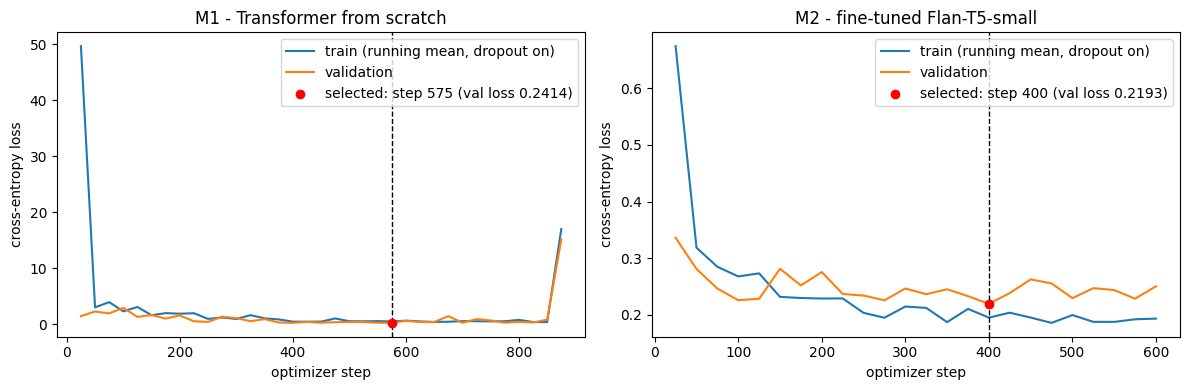

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
titles = {"m1_scratch": "M1 - Transformer from scratch", "m2_finetuned": "M2 - fine-tuned Flan-T5-small"}
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h["step"], h["train_loss"], label="train (running mean, dropout on)")
    ax.plot(h["step"], h["val_loss"], label="validation")
    b = h["best_step"]
    ax.axvline(b, color="k", ls="--", lw=1)
    ax.scatter([b], [h["best_val_loss"]], color="red", zorder=5, label=f"selected: step {b} (val loss {h['best_val_loss']:.4f})")
    ax.set_xlabel("optimizer step"); ax.set_ylabel("cross-entropy loss"); ax.set_title(titles[name]); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR / "loss_curves_m1_m2.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
rows = []
for name, h in histories.items():
    c, i = h["config"], h["val_loss"].index(h["best_val_loss"])
    rows.append({
        "system": name, "architecture": "T5 encoder-decoder (Flan-T5-small config: 8+8 layers, d_model 512, d_ff 1024, 6 heads)",
        "parameters": h["n_params"], "init": c["init"], "loss": "token-level cross-entropy",
        "optimizer": "AdamW (wd 0.01), linear warmup 6% + linear decay", "learning_rate": c["lr"], "batch_size": c["batch_size"],
        "max_epochs": c["epochs"], "steps_per_epoch": h["steps_per_epoch"], "steps_run": h["step"][-1],
        "epochs_run": round(h["step"][-1] / h["steps_per_epoch"], 2), "stopped_early": h["stopped_early"],
        "selected_step": h["best_step"], "selected_epoch": round(h["epoch"][i], 2), "selected_val_loss": round(h["best_val_loss"], 4),
        "train_loss_at_selected": round(h["train_loss"][i], 4), "val_acc_at_selected": round(h["val_acc"][i], 4),
        "final_train_loss": round(h["train_loss"][-1], 4), "final_val_loss": round(h["val_loss"][-1], 4),
        "grad_clip": c["grad_clip"], "seed": c["seed"], "max_source_len": c["max_source_len"], "max_target_len": c["max_target_len"],
        "train_seconds": round(h["train_seconds"]),
    })
setup = pd.DataFrame(rows).set_index("system").T
setup.to_csv(TABLES_DIR / "training_setup_m1_m2.csv"); display(setup)

system,m1_scratch,m2_finetuned
architecture,T5 encoder-decoder (Flan-T5-small config: 8+8 ...,T5 encoder-decoder (Flan-T5-small config: 8+8 ...
parameters,60511616,76961152
init,scratch,pretrained
loss,token-level cross-entropy,token-level cross-entropy
optimizer,"AdamW (wd 0.01), linear warmup 6% + linear decay","AdamW (wd 0.01), linear warmup 6% + linear decay"
learning_rate,0.001,0.0003
batch_size,32,32
max_epochs,30,10
steps_per_epoch,173,173
steps_run,875,600


## 3. M3: retrieval-augmented generation
For each question, BM25 retrieves chunks **from the question's own state index using only the question text**. The best chunk of each of the top-k distinct statutes is appended to the M2 input
(`state: .. question: .. context: [1] .. [2] ..`), with the question first and the remaining 512-token budget split equally among the k passages. The **fine-tuned M2 weights are used unchanged**, as specified.
k is chosen **on the validation set only**, by highest validation macro-F1 among k >= 1 (ties -> smaller k); k = 0 is shown for reference.

In [9]:
retrieved = {s: cache_retrieval(splits[s], TABLES_DIR / f"retrieval_{s}.jsonl") for s in ("val", "test")}
def ret_table(s):
    ranked = [M.statute_ranking(x["hits"]) for x in retrieved[s]]
    return M.retrieval_metrics(ranked, [r["gold_statute_idx"] for r in splits[s]])
ret = pd.DataFrame({s: ret_table(s) for s in ("val", "test")}).round(3)
ret.to_csv(TABLES_DIR / "retrieval_metrics.csv"); display(ret)

states:   0%|          | 0/48 [00:00<?, ?it/s]

states:   0%|          | 0/48 [00:00<?, ?it/s]

,val,test
hit@1,0.106,0.109
recall@1,0.064,0.058
hit@3,0.209,0.197
recall@3,0.134,0.119
hit@5,0.280,0.258
recall@5,0.192,0.161
hit@10,0.386,0.348
recall@10,0.275,0.229
mrr,0.188,0.181


In [10]:
m2, tok2 = load_best(MODELS_DIR / "m2_finetuned", device)
rows = []
for k in (0, 1, 2, 3, 5):
    recs = make_rag_records(splits["val"], retrieved["val"], tok2, k)
    p = generate(m2, tok2, [r["input_text"] for r in recs], device, max_source_len=512)
    rows.append({"k": k, **M.answer_metrics([r["target_text"] for r in recs], p)})
k_sweep = pd.DataFrame(rows).set_index("k").round(3)
k_sweep.to_csv(TABLES_DIR / "m3_k_sweep_val.csv")
BEST_K = int(k_sweep.loc[1:, "macro_f1"].idxmax())
display(k_sweep[["accuracy", "macro_f1", "mcc", "pred_yes_rate", "invalid_rate"]]); print("selected k =", BEST_K)
ex = make_rag_records(splits["val"][:1], retrieved["val"][:1], tok2, BEST_K)[0]["input_text"]
print(len(tok2(ex)["input_ids"]), "tokens in one example input\n", ex[:500])

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


,accuracy,macro_f1,mcc,pred_yes_rate,invalid_rate
k,,,,,
0,0.788,0.712,0.448,0.192,0.000
1,0.729,0.697,0.406,0.380,0.000
2,0.740,0.715,0.452,0.405,0.002
3,0.712,0.687,0.399,0.417,0.002
5,0.731,0.707,0.441,0.422,0.000


selected k = 2
257 tokens in one example input
 state: Alabama question: Is it specified whether a landlord waives their right to evict for nonpayment of rent by accepting partial payment of rent? context: [1] Section 35-9A-461Landlord's action for eviction, rent, monetary damages, or other relief. (a) A landlord's action for eviction, rent, monetary damages, or other relief relating to a tenancy subject to this chapter shall be governed by the Alabama Rules of Civil Procedure and the Alabama Rules of Appellate Procedure except as modified by


## 4. Evaluation on the test set (one pass, all systems)
**Metrics.** *Accuracy = exact match*: normalised prediction equals the gold label. *Token-F1*: SQuAD-style word overlap (equals EM for one-word answers; it would under-score a correct paraphrase such as "Yes, it does").
*Macro-F1 / F1(yes)*: protect against majority-class gaming (test is 62.7% "no"). *MCC*: chance-corrected. *Invalid rate*: outputs that are neither yes nor no (counted wrong).
95% intervals resample **question groups** (cluster bootstrap) because the test set contains only 23 distinct question texts; differences use a paired group bootstrap (exact McNemar shown for reference).
**Limitations:** few independent questions, Yes/No hides whether the reasoning was right, and no metric here checks citation quality (see the extension).

In [11]:
test = splits["test"]
retr = retrieved["test"]
golds = [r["target_text"] for r in test]
groups = np.array([r["question_group"] for r in test])
preds = {}
m1, tok1 = load_best(MODELS_DIR / "m1_scratch", device)
preds["M1 scratch"] = generate(m1, tok1, [r["input_text"] for r in test], device, 128)
preds["M2 fine-tuned"] = generate(m2, tok2, [r["input_text"] for r in test], device, 128)
rag_test = make_rag_records(test, retr, tok2, BEST_K)
N3 = f"M3 RAG (k={BEST_K})"
preds[N3] = generate(m2, tok2, [r["input_text"] for r in rag_test], device, 512)
names = list(preds)
print({n: pd.Series(p).str.lower().str.strip(" .").value_counts().to_dict() for n, p in preds.items()})

Loading weights:   0%|          | 0/189 [00:00<?, ?it/s]

{'M1 scratch': {'no': 445, 'yes': 244}, 'M2 fine-tuned': {'no': 467, 'yes': 222}, 'M3 RAG (k=2)': {'yes': 356, 'no': 333}}


In [12]:
train_golds = [r["target_text"] for r in splits["train"]]
mb = M.majority_baseline(train_golds, golds); MAJ = f"Majority (always '{mb.pop('label')}')"
rows = {MAJ: mb}
for n, p in preds.items():
    rows[n] = M.answer_metrics(golds, p)
res = pd.DataFrame(rows).T
correct = {n: np.array([M.normalize_label(p) == M.normalize_label(g) for p, g in zip(ps, golds)]) for n, ps in preds.items()}
maj_correct = np.array([M.normalize_label(g) == M.normalize_label(MAJ.split("'")[1]) for g in golds])
for n, c in {MAJ: maj_correct, **correct}.items():
    lo, hi = M.cluster_bootstrap_ci(c, groups); res.loc[n, "acc_95CI"] = f"[{lo:.3f}, {hi:.3f}]"
res = res.round(3); res.to_csv(TABLES_DIR / "test_results.csv"); display(res)

,n,accuracy,exact_match,token_f1,f1_yes,f1_no,macro_f1,mcc,pred_yes_rate,invalid_rate,acc_95CI
Majority (always 'no'),689.0,0.627,0.627,0.627,0.000,0.771,0.385,0.000,0.000,0.0,"[0.441, 0.783]"
M1 scratch,689.0,0.790,0.790,0.790,0.711,0.835,0.773,0.546,0.354,0.0,"[0.673, 0.883]"
M2 fine-tuned,689.0,0.743,0.743,0.743,0.630,0.803,0.717,0.438,0.322,0.0,"[0.597, 0.872]"
M3 RAG (k=2),689.0,0.685,0.685,0.685,0.646,0.716,0.681,0.392,0.517,0.0,"[0.566, 0.803]"


In [13]:
rows = []
allc = {MAJ: maj_correct, **correct}; an = list(allc)
for i in range(len(an)):
    for j in range(i + 1, len(an)):
        a, b = an[i], an[j]
        rows.append({"A": a, "B": b, **M.paired_cluster_bootstrap(allc[a], allc[b], groups),
                     **{f"mcnemar_{k}": v for k, v in M.mcnemar_exact(allc[a], allc[b]).items()}})
sig = pd.DataFrame(rows).round(4); sig.to_csv(TABLES_DIR / "test_significance.csv", index=False); display(sig)

,A,B,diff,ci_low,ci_high,p_value,mcnemar_a_only_correct,mcnemar_b_only_correct,mcnemar_p_value
0,Majority (always 'no'),M1 scratch,-0.1626,-0.4011,0.0563,0.1434,66,178,0.0000
1,Majority (always 'no'),M2 fine-tuned,-0.1161,-0.3324,0.0720,0.2496,71,151,0.0000
2,Majority (always 'no'),M3 RAG (k=2),-0.0581,-0.3221,0.1673,0.6484,158,198,0.0386
3,M1 scratch,M2 fine-tuned,0.0464,-0.1153,0.2119,0.5728,115,83,0.0273
4,M1 scratch,M3 RAG (k=2),0.1045,-0.0190,0.2173,0.0964,152,80,0.0000
5,M2 fine-tuned,M3 RAG (k=2),0.0581,-0.0732,0.1699,0.3616,88,48,0.0008


In [14]:
# Per-question-group accuracy (23 groups): shows how much depends on a few question texts
g = pd.DataFrame({"group": groups, "question": [r["question"] for r in test], "gold": golds, **correct})
per_group = g.groupby("group").agg(question=("question", "first"), n=("gold", "size"), yes_rate=("gold", lambda s: (s == "yes").mean()),
                                  **{n: (n, "mean") for n in names}).round(2)
per_group.to_csv(TABLES_DIR / "test_per_group.csv"); display(per_group)

,question,n,yes_rate,M1 scratch,M2 fine-tuned,M3 RAG (k=2)
group,,,,,,
18,Is it specified whether a tenant forfeits the ...,13,1.00,1.00,1.00,1.00
25,Does the law regulate circumstances in which e...,6,0.17,0.83,0.83,0.50
45,Does state/territory eviction law explicitly r...,37,1.00,1.00,0.00,0.76
68,Does the law require landlords to describe rep...,34,0.15,0.71,0.15,0.18
75,Is it unlawful to evict a tenant based on mili...,42,0.26,0.74,0.74,0.64
86,Secondary methods of service are defined as th...,30,0.10,0.90,0.90,0.90
96,Does the law regulate circumstances in which e...,6,0.83,0.17,0.17,0.83
104,Primary methods of service are defined as thos...,21,0.19,0.81,0.81,0.81
111,Is the term 'Eviction order' used to refer to ...,42,0.02,0.98,0.98,0.95


## 5. Error analysis (at least 5 questions) with retrieval attribution for M3

In [15]:
gold_sets = [set(r["gold_statute_idx"]) for r in test]
used = [top_statute_hits(x["hits"], BEST_K) for x in retr]
retr_hit = np.array([bool({h["statute_idx"] for h in u} & gs) for u, gs in zip(used, gold_sets)])
df = pd.DataFrame({"m2_ok": correct["M2 fine-tuned"], "m3_ok": correct[N3], "retr_hit": retr_hit})
def label(r):
    if not r.m2_ok and r.m3_ok: return "A: M3 fixes M2 (gold in context)" if r.retr_hit else "A: M3 fixes M2 (gold NOT in context)"
    if r.m2_ok and not r.m3_ok: return "B: M3 breaks M2 (gold in context)" if r.retr_hit else "B: M3 breaks M2 (gold NOT in context)"
    if not r.m2_ok and not r.m3_ok: return "C: both wrong - generation error (gold in context)" if r.retr_hit else "C: both wrong - retrieval error (gold missed)"
    return "D: both right"
df["case"] = df.apply(label, axis=1)
attr = df["case"].value_counts().sort_index().rename("n").to_frame(); attr["share"] = (attr["n"] / len(df)).round(3)
attr.to_csv(TABLES_DIR / "m3_error_attribution.csv"); display(attr)
cond = df.groupby("retr_hit")["m3_ok"].agg(["mean", "size"]).round(3).rename(index={True: "gold in top-k", False: "gold missed"}); display(cond)

,n,share
case,,
A: M3 fixes M2 (gold NOT in context),34,0.049
A: M3 fixes M2 (gold in context),14,0.020
B: M3 breaks M2 (gold NOT in context),71,0.103
B: M3 breaks M2 (gold in context),17,0.025
C: both wrong - generation error (gold in context),31,0.045
C: both wrong - retrieval error (gold missed),98,0.142
D: both right,424,0.615


,mean,size
retr_hit,,
gold missed,0.707,576
gold in top-k,0.575,113


In [16]:
# Deterministic selection: up to 2 per non-"both right" category; guarantees >= 5 cases whenever >= 5 exist
rng = np.random.default_rng(42); picks = []
for case in sorted(df["case"].unique()):
    if case.startswith("D"): continue
    ids = df.index[df["case"] == case].to_numpy()
    picks += [int(i) for i in rng.choice(ids, size=min(2, len(ids)), replace=False)]
if len(picks) < 5:                      # top up from "both right" so at least 5 questions are analysed
    ids = [i for i in df.index[df["case"].str.startswith("D")] if i not in picks]
    picks += [int(i) for i in rng.choice(ids, size=5 - len(picks), replace=False)]
print(f"{len(picks)} analysed questions")
for i in picks:
    r = test[i]
    print("=" * 100); print(f"[{df.loc[i, 'case']}]  ({r['id']}, {r['state']})")
    print("Q:", r["question"]); print("gold:", r["answer"], "| M1:", preds["M1 scratch"][i], "| M2:", preds["M2 fine-tuned"][i], "| M3:", preds[N3][i])
    print("GOLD provision(s):", [(s["citation"], s["excerpt"][:200]) for s in r["statutes"]])
    for rank, h in enumerate(used[i], 1):
        print(f"  retrieved #{rank} {'(GOLD)' if h['statute_idx'] in gold_sets[i] else ''} {h['citation']} :: {h['text'][:200]}")
pd.DataFrame({"id": [test[i]["id"] for i in picks], "case": [df.loc[i, "case"] for i in picks]}).to_csv(TABLES_DIR / "error_analysis_picks.csv", index=False)

12 analysed questions
[A: M3 fixes M2 (gold NOT in context)]  (q-2582, Arkansas)
Q: Is it unlawful to evict a tenant based on military or veteran status?
gold: yes | M1: no | M2: no | M3: yes
GOLD provision(s): [('ARK. CODE § 12-62-714(A)(1)', '(a)(1) Except as provided in subdivision (a)(2) of this section, a landlord may not evict or take and hold property of a service member or his or her dependents for nonpayment of rent during the servi'), ('ARK. CODE § 16-123-310', '(a) Because of race, color, religion, sex, familial status, or national origin a person shall not:(1) Refuse to sell or rent a dwelling to a person who has made a bona fide offer;(2) Refuse to negotia'), ('ARK. CODE § 16-123-314', '(a) A person shall not discriminate in the sale or rental or otherwise make unavailable or deny a dwelling to a buyer or renter because of a disability of:(1) That buyer or renter;(2) A person residin'), ('ARK. CODE §18-16-112(B)(1)', "(b) If a residential tenant, an applicant for a residen

## 6. Optional extension: legal citations (reported separately from the answer metrics)
Citation = the top-ranked retrieved statute (id, citation string, section path). **Correct provision** = its `statute_idx` is one of the annotated gold statutes. Whether a provision truly *supports*
the answer is judged by hand on a 40-question sample (`citation_manual_annotation.csv`), because gold statutes are only guaranteed to support the gold answer.

In [17]:
cits = [cite(x["hits"], 1)[0] for x in retr]
cit_ok = np.array([c["statute_idx"] in gs for c, gs in zip(cits, gold_sets)])
top3_ok = np.array([bool({c["statute_idx"] for c in cite(x["hits"], 3)} & gs) for x, gs in zip(retr, gold_sets)])
lo, hi = M.cluster_bootstrap_ci(cit_ok, groups)
cit = pd.Series({"citation_correct@1": cit_ok.mean(), "95CI_low": lo, "95CI_high": hi, "any_gold_in_top3_cited": top3_ok.mean(),
                 "answer_correct_AND_citation_correct": (cit_ok & correct[N3]).mean(),
                 "answer_correct_given_citation_correct": correct[N3][cit_ok].mean() if cit_ok.any() else np.nan,
                 "answer_correct_given_citation_wrong": correct[N3][~cit_ok].mean() if (~cit_ok).any() else np.nan}).round(3)
cit.to_csv(TABLES_DIR / "citation_results.csv", header=["value"]); display(cit)
rng = np.random.default_rng(42); sel = sorted(int(i) for i in rng.choice(len(test), size=40, replace=False))
sheet = pd.DataFrame([{"id": test[i]["id"], "state": test[i]["state"], "question": test[i]["question"], "gold_answer": golds[i],
                       "m3_answer": preds[N3][i], "cited_citation": cits[i]["citation"], "cited_path": cits[i]["path"],
                       "cited_text": top_statute_hits(retr[i]["hits"], 1)[0]["text"], "is_gold_provision(auto)": bool(cit_ok[i]),
                       "supports_answer(manual)": ""} for i in sel])
ann = TABLES_DIR / "citation_manual_annotation.csv"
if ann.exists():                                  # never overwrite hand labels on a re-run
    print("annotation sheet already exists - kept:", ann)
else:
    sheet.to_csv(ann, index=False); print("annotation sheet written:", ann)

,0
citation_correct@1,0.109
95CI_low,0.079
95CI_high,0.143
any_gold_in_top3_cited,0.197
answer_correct_AND_citation_correct,0.064
answer_correct_given_citation_correct,0.587
answer_correct_given_citation_wrong,0.697


annotation sheet written: /content/drive/MyDrive/NLP-final-2026-main/reports/tables/citation_manual_annotation.csv


## 7. Final report (generated from the results above)
The text below is produced from the computed tables, so it always matches the numbers. It states what the data support and does not over-claim.

In [18]:
def pct(x): return f"{100 * x:.1f}%"
H1, H2 = histories["m1_scratch"], histories["m2_finetuned"]
def tr_info(h):
    i = h["val_loss"].index(h["best_val_loss"])
    return h["best_step"], h["epoch"][i], h["train_loss"][i], h["best_val_loss"], h["val_acc"][i], h["stopped_early"]
val_major = max(np.mean([r["target_text"] == "no" for r in splits["val"]]), np.mean([r["target_text"] == "yes" for r in splits["val"]]))
L = []
L.append("### Training (M1 vs M2)")
for nm, h in (("M1 (scratch)", H1), ("M2 (fine-tuned)", H2)):
    s, e, trl, vl, va, es = tr_info(h)
    L.append(f"- **{nm}**: selected checkpoint at step {s} (epoch {e:.1f}); train loss {trl:.3f}, validation loss {vl:.3f} (gap {vl - trl:+.3f}); validation accuracy {pct(va)} "
             f"vs the validation majority baseline {pct(val_major)}; {'stopped early' if es else 'ran all epochs'} after {h['step'][-1]} steps.")
for nm, h in (("M1", H1), ("M2", H2)):
    rise = h["val_loss"][-1] - h["best_val_loss"]
    L.append(f"- {nm}: validation loss ended at {h['val_loss'][-1]:.3f} vs its minimum {h['best_val_loss']:.3f} ("
             + ("it rose after the minimum, i.e. overfitting; the lowest-validation-loss checkpoint is therefore used)." if rise > 0.005 else "no clear rise after the minimum)."))
L.append("\n### Test results")
maj_acc = res.loc[MAJ, "accuracy"]
for n in names:
    lo, hi = M.cluster_bootstrap_ci(correct[n], groups); r_ = res.loc[n]
    d_ = M.paired_cluster_bootstrap(correct[n], maj_correct, groups)          # model - majority, paired over question groups
    verdict = ("is not distinguishable from the majority baseline" if d_["ci_low"] <= 0 <= d_["ci_high"] else ("is significantly above the majority baseline" if d_["diff"] > 0 else "is significantly below the majority baseline"))
    L.append(f"- **{n}**: accuracy {pct(r_['accuracy'])} (95% CI {pct(lo)}-{pct(hi)}), macro-F1 {r_['macro_f1']:.3f}, MCC {r_['mcc']:.3f}, predicts 'yes' for {pct(r_['pred_yes_rate'])} of questions, "
             f"invalid outputs {pct(r_['invalid_rate'])}; it {verdict} ({pct(maj_acc)}, {MAJ}).")
L.append("\n### Comparisons (paired group bootstrap, 95% CI of accuracy difference)")
for _, r_ in sig[(sig.A != MAJ) & (sig.B != MAJ)].iterrows():
    sup = "statistically supported" if (r_.ci_low > 0 or r_.ci_high < 0) else "not statistically supported"
    L.append(f"- {r_.A} - {r_.B}: {r_['diff'] * 100:+.1f} pts, CI [{r_.ci_low * 100:+.1f}, {r_.ci_high * 100:+.1f}], p={r_.p_value:.3f} -> {sup}.")
L.append("\n### Retrieval and M3")
L.append(f"- BM25 on test: gold statute in top-1 / top-3 / top-5 / top-10 for {pct(ret.loc['hit@1','test'])} / {pct(ret.loc['hit@3','test'])} / {pct(ret.loc['hit@5','test'])} / {pct(ret.loc['hit@10','test'])} of questions; MRR {ret.loc['mrr','test']:.3f}. "
         f"With k={BEST_K} passages given to M3, the gold statute was in the context for {pct(retr_hit.mean())} of test questions.")
for key, nm in ((True, "gold in context"), (False, "gold missing")):
    if (retr_hit == key).any():
        L.append(f"- M3 accuracy when {nm}: {pct(cond.loc['gold in top-k' if key else 'gold missed', 'mean'])} (n={int(cond.loc['gold in top-k' if key else 'gold missed', 'size'])}).")
L.append("- Error attribution of M3 (A/B: M3 changes M2's answer; C: both wrong; D: both right): " + "; ".join(f"{k} = {v}" for k, v in attr["n"].items()) + ". "
         "'Retrieval error' = the gold statute never reached the model; 'generation error' = it was in the context but the answer is still wrong. The analysed examples are printed in section 5.")
L.append("\n### Citation extension (separate from the answer metrics)")
L.append(f"- The top-ranked retrieved statute is a gold provision for {pct(cit['citation_correct@1'])} of test questions (95% CI {pct(cit['95CI_low'])}-{pct(cit['95CI_high'])}); "
         f"a gold provision appears among the top-3 cited for {pct(cit['any_gold_in_top3_cited'])}; answer and citation both correct for {pct(cit['answer_correct_AND_citation_correct'])}.")
lab = pd.read_csv(ann)["supports_answer(manual)"].dropna().astype(str).str.strip().str.lower()
lab = lab[lab != ""]
L.append(f"- Manual 'supports the answer' labels: {len(lab)} of 40 completed" + (f" ({', '.join(f'{k}: {v}' for k, v in lab.value_counts().items())})." if len(lab) else " - fill `supports_answer(manual)` in `citation_manual_annotation.csv` and re-run this cell."))
L.append("\n### Limitations")
L.append(f"- The answers are binary and the test set has only {len(te_q)} distinct question texts ({len(test)} rows), so intervals are wide and per-group variation matters (`test_per_group.csv`). "
         f"{int((sim > 0.9).sum())} test question texts are near-duplicates (TF-IDF cosine > 0.9) of a training question; exact overlap is {len(exact_overlap)}.")
L.append("- M3 reuses M2 as specified; M2 never saw a context field, so the added passages may be ignored or act as noise. BM25 is lexical and legal text paraphrases statutory wording, which limits recall. Passages are truncated to fit 512 tokens.")
L.append("- Validation and test label distributions differ (validation is mostly 'no'), so validation and test scores are not directly comparable.")
report_md = "\n".join(L)
(ROOT / "reports" / "final_report.md").write_text("# Results summary (auto-generated)\n\n" + report_md, encoding="utf-8")
display(Markdown(report_md))

### Training (M1 vs M2)
- **M1 (scratch)**: selected checkpoint at step 575 (epoch 3.3); train loss 0.502, validation loss 0.241 (gap -0.260); validation accuracy 82.8% vs the validation majority baseline 70.6%; stopped early after 875 steps.
- **M2 (fine-tuned)**: selected checkpoint at step 400 (epoch 2.3); train loss 0.195, validation loss 0.219 (gap +0.024); validation accuracy 78.8% vs the validation majority baseline 70.6%; stopped early after 600 steps.
- M1: validation loss ended at 15.122 vs its minimum 0.241 (it rose after the minimum, i.e. overfitting; the lowest-validation-loss checkpoint is therefore used).
- M2: validation loss ended at 0.250 vs its minimum 0.219 (it rose after the minimum, i.e. overfitting; the lowest-validation-loss checkpoint is therefore used).

### Test results
- **M1 scratch**: accuracy 79.0% (95% CI 67.3%-88.3%), macro-F1 0.773, MCC 0.546, predicts 'yes' for 35.4% of questions, invalid outputs 0.0%; it is not distinguishable from the majority baseline (62.7%, Majority (always 'no')).
- **M2 fine-tuned**: accuracy 74.3% (95% CI 59.7%-87.2%), macro-F1 0.717, MCC 0.438, predicts 'yes' for 32.2% of questions, invalid outputs 0.0%; it is not distinguishable from the majority baseline (62.7%, Majority (always 'no')).
- **M3 RAG (k=2)**: accuracy 68.5% (95% CI 56.6%-80.3%), macro-F1 0.681, MCC 0.392, predicts 'yes' for 51.7% of questions, invalid outputs 0.0%; it is not distinguishable from the majority baseline (62.7%, Majority (always 'no')).

### Comparisons (paired group bootstrap, 95% CI of accuracy difference)
- M1 scratch - M2 fine-tuned: +4.6 pts, CI [-11.5, +21.2], p=0.573 -> not statistically supported.
- M1 scratch - M3 RAG (k=2): +10.4 pts, CI [-1.9, +21.7], p=0.096 -> not statistically supported.
- M2 fine-tuned - M3 RAG (k=2): +5.8 pts, CI [-7.3, +17.0], p=0.362 -> not statistically supported.

### Retrieval and M3
- BM25 on test: gold statute in top-1 / top-3 / top-5 / top-10 for 10.9% / 19.7% / 25.8% / 34.8% of questions; MRR 0.181. With k=2 passages given to M3, the gold statute was in the context for 16.4% of test questions.
- M3 accuracy when gold in context: 57.5% (n=113).
- M3 accuracy when gold missing: 70.7% (n=576).
- Error attribution of M3 (A/B: M3 changes M2's answer; C: both wrong; D: both right): A: M3 fixes M2 (gold NOT in context) = 34; A: M3 fixes M2 (gold in context) = 14; B: M3 breaks M2 (gold NOT in context) = 71; B: M3 breaks M2 (gold in context) = 17; C: both wrong - generation error (gold in context) = 31; C: both wrong - retrieval error (gold missed) = 98; D: both right = 424. 'Retrieval error' = the gold statute never reached the model; 'generation error' = it was in the context but the answer is still wrong. The analysed examples are printed in section 5.

### Citation extension (separate from the answer metrics)
- The top-ranked retrieved statute is a gold provision for 10.9% of test questions (95% CI 7.9%-14.3%); a gold provision appears among the top-3 cited for 19.7%; answer and citation both correct for 6.4%.
- Manual 'supports the answer' labels: 0 of 40 completed - fill `supports_answer(manual)` in `citation_manual_annotation.csv` and re-run this cell.

### Limitations
- The answers are binary and the test set has only 23 distinct question texts (689 rows), so intervals are wide and per-group variation matters (`test_per_group.csv`). 2 test question texts are near-duplicates (TF-IDF cosine > 0.9) of a training question; exact overlap is 0.
- M3 reuses M2 as specified; M2 never saw a context field, so the added passages may be ignored or act as noise. BM25 is lexical and legal text paraphrases statutory wording, which limits recall. Passages are truncated to fit 512 tokens.
- Validation and test label distributions differ (validation is mostly 'no'), so validation and test scores are not directly comparable.

In [19]:
print("Saved to", ROOT)
for p in sorted([*TABLES_DIR.glob("*.csv"), *FIGURES_DIR.glob("loss_curves_m1_m2.png"), ROOT / "reports" / "final_report.md"]):
    print(" -", p.relative_to(ROOT))

Saved to /content/drive/MyDrive/NLP-final-2026-main
 - reports/figures/loss_curves_m1_m2.png
 - reports/final_report.md
 - reports/tables/citation_manual_annotation.csv
 - reports/tables/citation_results.csv
 - reports/tables/corpus_index_stats.csv
 - reports/tables/eda_overview.csv
 - reports/tables/error_analysis_picks.csv
 - reports/tables/m3_error_attribution.csv
 - reports/tables/m3_k_sweep_val.csv
 - reports/tables/qa_examples.csv
 - reports/tables/retrieval_metrics.csv
 - reports/tables/split_summary.csv
 - reports/tables/test_per_group.csv
 - reports/tables/test_results.csv
 - reports/tables/test_significance.csv
 - reports/tables/training_setup_m1_m2.csv
